# 02. Model Training: Hand Gesture Recognition

**Mục tiêu:** xây dựng, huấn luyện và đánh giá mô hình nhận diện cử chỉ tay tĩnh từ ảnh bằng **PyTorch**.

Notebook này sử dụng ảnh trong dataset đã có. Ảnh gốc chỉ được đọc, không di chuyển hoặc chỉnh sửa.

## Quy trình

```text
Dataset folders
      │
      ▼
Load ảnh bằng ImageFolder
      │
      ▼
Train / Validation split
      │
      ▼
Transform ảnh + DataLoader
      │
      ▼
Build CNN
      │
      ▼
Train từng epoch
      │
      ▼
Lưu checkpoint tốt nhất
      │
      ▼
Evaluate trên validation set
```

**Lưu ý:** preprocessing cơ bản (RGB, resize, tensor, normalize) được thực hiện trực tiếp bằng `torchvision.transforms` khi DataLoader đọc ảnh. Không cần tạo thêm bản sao ảnh đã xử lý.


## Cell 1. Import thư viện

Nạp các thư viện:
- PyTorch để xây dựng và huấn luyện neural network.
- Torchvision để đọc ảnh và biến đổi ảnh.
- Scikit-learn để chia dữ liệu có phân tầng và tính metric.
- Matplotlib để vẽ loss, accuracy và confusion matrix.


In [1]:
import os
import random
import copy
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.14.1+cpu
CUDA available: False


## Cell 2. Cấu hình thiết bị và seed

Ưu tiên GPU CUDA nếu có, nếu không sẽ chạy bằng CPU.

Các tham số chính:
- `IMAGE_SIZE`: kích thước ảnh đầu vào.
- `BATCH_SIZE`: số ảnh trong một batch.
- `EPOCHS`: số vòng huấn luyện.
- `LEARNING_RATE`: tốc độ cập nhật trọng số.

Có thể giảm `BATCH_SIZE` nếu GPU báo thiếu bộ nhớ.


In [25]:
%pip uninstall -y torch torchvision torchaudio

Found existing installation: torch 2.14.1
Uninstalling torch-2.14.1:
  Successfully uninstalled torch-2.14.1
Found existing installation: torchvision 0.29.1
Uninstalling torchvision-0.29.1:
  Successfully uninstalled torchvision-0.29.1
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.
You can safely remove it manually.


In [26]:
%pip install torch==2.14.1 torchvision==0.29.1 --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB 9.5 MB/s eta 0:04:33
   ---------------------------------------- 0.0/2.6 GB 29.6 MB/s eta 0:01:28
   ---------------------------------------- 0.0/2.6 GB 28.4 MB/s eta 0:01:31
   ---------------------------------------- 0.0/2.6 GB 29.5 MB/s eta 0:01:28
   ---------------------------------------- 0.0/2.6 GB 33.0 MB/s eta 0:01:18
    --------------------------------------- 0.0/2.6 GB 32.2 MB/s eta 0:01:20
    --------------------------------------- 0.0/2.6 GB 33.0 MB/s eta 0:01:18
    --------------------------------------- 0.1/2.6 GB 33.0 MB/s eta 0:01:18
    --------------------------------------- 0.1/2.6 GB 33.0 MB/s eta 0:01:18
   - -------------------------------------- 0.1/2.6 GB 33.4 MB/s eta 0:01:16
   - -------------------------------------- 0.1/2.6 GB 33.3 MB/s eta 0:01:16
   - ---------------------

In [28]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not detected")

PyTorch: 2.14.1+cpu
CUDA: None
GPU available: False
GPU: Not detected


In [29]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 1e-3
VALIDATION_SIZE = 0.2
NUM_WORKERS = 0  # Phù hợp để chạy ổn định trên Windows/Jupyter

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


## Cell 3. Khai báo đường dẫn

Notebook giả định cấu trúc:

```text
project/
├── dataset/
│   └── asl_alphabet_train/
│       ├── A/
│       ├── B/
│       └── ...
├── models/
└── notebooks/
    └── 02_model_training.ipynb
```

Nếu tên hoặc vị trí thư mục dataset khác, hãy sửa `TRAIN_DIR`.

Thư mục `models/` là nơi lưu checkpoint của mô hình đã huấn luyện, không phải nơi chứa dataset.


In [3]:
PROJECT_ROOT = Path("..").resolve()
TRAIN_DIR = PROJECT_ROOT / "dataset" / "asl_alphabet_train"
MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"
CLASS_NAMES_PATH = MODEL_DIR / "class_names.json"
HISTORY_PATH = MODEL_DIR / "training_history.csv"

if not TRAIN_DIR.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset: {TRAIN_DIR}\n"
        "Hãy kiểm tra lại đường dẫn TRAIN_DIR."
    )

print("Train data:", TRAIN_DIR)
print("Model output:", MODEL_DIR)


Train data: C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphabet_train
Model output: C:\Dev\nhan_dien_cu_chi_tay\models


## Cell 4. Đọc dataset và lấy danh sách nhãn

`ImageFolder` tự động:
- Đọc ảnh từ từng thư mục lớp.
- Dùng tên thư mục làm nhãn.
- Tạo ánh xạ `class_to_idx`.

Ví dụ: thư mục `A` có thể được ánh xạ thành nhãn số `0`. Ánh xạ thực tế được lấy từ dataset, không tự giả định thứ tự.


In [4]:
base_dataset = datasets.ImageFolder(root=str(TRAIN_DIR))

class_names = base_dataset.classes
class_to_idx = base_dataset.class_to_idx
targets = np.array(base_dataset.targets)

NUM_CLASSES = len(class_names)

print("Number of images:", len(base_dataset))
print("Number of classes:", NUM_CLASSES)
print("Class mapping:")
print(class_to_idx)

if NUM_CLASSES < 2:
    nested_datasets = []

    for child in TRAIN_DIR.iterdir():
        if child.is_dir():
            candidate = datasets.ImageFolder(root=str(child))
            if len(candidate.classes) >= 2:
                nested_datasets.append((child, candidate))

    if len(nested_datasets) == 1:
        TRAIN_DIR, base_dataset = nested_datasets[0]

        class_names = base_dataset.classes
        class_to_idx = base_dataset.class_to_idx
        targets = np.array(base_dataset.targets)
        NUM_CLASSES = len(class_names)

        print(f"Using nested dataset folder: {TRAIN_DIR}")
        print("Number of classes:", NUM_CLASSES)
    else:
        raise ValueError(
            f"ImageFolder chỉ tìm thấy {NUM_CLASSES} class tại {TRAIN_DIR}. "
            "Hãy đặt TRAIN_DIR trỏ tới thư mục cha trực tiếp của các thư mục class "
            "(ví dụ: A/, B/, C/)."
        )


Number of images: 87000
Number of classes: 1
Class mapping:
{'asl_alphabet_train': 0}
Using nested dataset folder: C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphabet_train\asl_alphabet_train
Number of classes: 29


## Cell 5. Kiểm tra phân bố nhãn trước khi chia tập

Kiểm tra số lượng ảnh trong mỗi class. Việc chia train/validation có phân tầng giúp giữ tỷ lệ lớp tương đối đồng đều ở hai tập.

Nếu một class có quá ít ảnh, cần xem xét dữ liệu trước khi chia.


In [5]:
class_counts = pd.Series(targets).value_counts().sort_index()
count_table = pd.DataFrame({
    "class_name": class_names,
    "image_count": [int(class_counts.get(i, 0)) for i in range(NUM_CLASSES)]
})

display(count_table)

print("Smallest class:", count_table["image_count"].min())
print("Largest class :", count_table["image_count"].max())


,class_name,image_count
0,A,3000
1,B,3000
2,C,3000
3,D,3000
4,E,3000
5,F,3000
6,G,3000
7,H,3000
8,I,3000
9,J,3000


Smallest class: 3000
Largest class : 3000


## Cell 6. Chia Train và Validation

Chia dữ liệu theo tỷ lệ mặc định 80% train và 20% validation.

`stratify=targets` giúp mỗi class xuất hiện trong cả hai tập theo tỷ lệ gần tương đương. Validation được dùng để theo dõi khả năng tổng quát hóa và chọn checkpoint tốt nhất, không dùng để cập nhật trọng số.


In [6]:
all_indices = np.arange(len(base_dataset))

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
    stratify=targets
)

print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Train ratio: {len(train_indices) / len(all_indices):.2%}")
print(f"Validation ratio: {len(val_indices) / len(all_indices):.2%}")


Train images: 69600
Validation images: 17400
Train ratio: 80.00%
Validation ratio: 20.00%


## Cell 7. Khai báo preprocessing và augmentation

Các phép biến đổi được áp dụng khi ảnh được nạp:
- Resize: đưa ảnh về cùng kích thước.
- ToTensor: chuyển ảnh thành tensor và đưa pixel về khoảng `[0, 1]`.
- Normalize: chuẩn hóa theo mean/std của ImageNet.
- Augmentation nhẹ trên train: thay đổi nhỏ góc xoay và vị trí để tăng khả năng tổng quát hóa.

Không dùng augmentation cho validation. Không lật ngang ảnh mặc định vì lật có thể làm thay đổi ý nghĩa hoặc hướng của một số cử chỉ.


In [7]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transforms are ready.")


Transforms are ready.


## Cell 8. Tạo Dataset và DataLoader

Tạo hai đối tượng `ImageFolder` riêng để train và validation có transform khác nhau, sau đó dùng chung danh sách chỉ số đã chia ở Cell 6.

`DataLoader` gom ảnh thành batch và nạp dữ liệu cho model.


In [8]:
train_dataset_full = datasets.ImageFolder(
    root=str(TRAIN_DIR),
    transform=train_transform
)

val_dataset_full = datasets.ImageFolder(
    root=str(TRAIN_DIR),
    transform=val_transform
)

# Đảm bảo thứ tự class của hai dataset giống nhau
assert train_dataset_full.class_to_idx == val_dataset_full.class_to_idx

train_dataset = Subset(train_dataset_full, train_indices.tolist())
val_dataset = Subset(val_dataset_full, val_indices.tolist())

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Train batches: 1088
Validation batches: 272


## Cell 9. Kiểm tra một batch dữ liệu

Lấy thử một batch để xác nhận:
- Tensor ảnh có dạng `[batch, channels, height, width]`.
- Số nhãn nằm trong khoảng hợp lệ.
- Ảnh sau preprocessing có đúng kích thước.

Nếu cell này chạy thành công, dữ liệu đã sẵn sàng đưa vào CNN.


In [9]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel min:", images.min().item())
print("Pixel max:", images.max().item())
print("Label examples:", labels[:10].tolist())

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.min().item() >= 0
assert labels.max().item() < NUM_CLASSES


Image batch shape: torch.Size([64, 3, 128, 128])
Label batch shape: torch.Size([64])
Pixel min: -2.1179039478302
Pixel max: 2.640000104904175
Label examples: [17, 21, 11, 6, 19, 11, 14, 24, 20, 9]


## Cell 10. Xây dựng mô hình CNN

Sử dụng CNN tự xây dựng để làm baseline đầu tiên.

Một CNN gồm:
1. Convolution: học đặc trưng như cạnh, đường nét và hình dạng bàn tay.
2. ReLU: thêm tính phi tuyến.
3. MaxPool: giảm kích thước feature map.
4. Adaptive pooling: đưa feature map về kích thước cố định.
5. Fully connected: dự đoán class.

Đầu ra có `NUM_CLASSES` giá trị. Mỗi giá trị là một logit, chưa phải xác suất.


In [10]:
class HandGestureCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = HandGestureCNN(NUM_CLASSES).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


HandGestureCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchN

## Cell 11. Kiểm tra forward pass

Cho một batch ảnh đi qua model mà chưa cập nhật trọng số.

Kết quả phải có dạng `[batch_size, NUM_CLASSES]`. Nếu shape đúng, kiến trúc CNN đã kết nối được với dữ liệu đầu vào.


In [11]:
model.eval()

with torch.no_grad():
    sample_logits = model(images[:4].to(DEVICE))

print("Output shape:", sample_logits.shape)
print("Expected shape:", (4, NUM_CLASSES))

assert sample_logits.shape == (4, NUM_CLASSES)


Output shape: torch.Size([4, 29])
Expected shape: (4, 29)


## Cell 12. Khai báo Loss và Optimizer

- `CrossEntropyLoss`: phù hợp với bài toán phân loại nhiều lớp, nhận logits và nhãn dạng số nguyên.
- `Adam`: cập nhật trọng số dựa trên gradient.
- `ReduceLROnPlateau`: giảm learning rate khi validation loss không cải thiện.

Không cần tự áp dụng Softmax trước `CrossEntropyLoss`.


In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss, optimizer and scheduler are ready.")


Loss, optimizer and scheduler are ready.


## Cell 13. Viết hàm train một epoch

Trong mỗi batch:
1. Đưa ảnh và nhãn lên thiết bị tính toán.
2. Xóa gradient cũ.
3. Forward: model dự đoán.
4. Tính loss.
5. Backward: tính gradient.
6. Optimizer cập nhật trọng số.

Hàm trả về loss trung bình và accuracy của epoch.


In [13]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(batch_images)
        loss = criterion(logits, batch_labels)

        loss.backward()
        optimizer.step()

        batch_size = batch_labels.size(0)
        running_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


## Cell 14. Viết hàm validation

Validation chạy ở chế độ `eval()` và `torch.no_grad()`:
- Không cập nhật trọng số.
- Không tính gradient.
- Đo loss và accuracy trên dữ liệu chưa dùng để cập nhật model.

Kết quả validation được dùng để theo dõi overfitting và lưu checkpoint tốt nhất.


In [14]:
def evaluate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)

            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            batch_size = batch_labels.size(0)
            running_loss += loss.item() * batch_size

            predictions = logits.argmax(dim=1)
            correct += (predictions == batch_labels).sum().item()
            total += batch_size

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


## Cell 15. Huấn luyện model

Mỗi epoch gồm một lượt train và một lượt validation.

Checkpoint chỉ được cập nhật khi validation loss tốt hơn kết quả tốt nhất trước đó. File lưu gồm:
- `model_state_dict`: trọng số model.
- `class_names`: thứ tự nhãn.
- `image_size`: kích thước đầu vào.
- `model_name`: tên kiến trúc.

Nếu dừng notebook giữa chừng, checkpoint tốt nhất đã lưu vẫn còn trên ổ đĩa.


In [15]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_model_state = None

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE
    )

    val_loss, val_acc = evaluate_one_epoch(
        model, val_loader, criterion, DEVICE
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save({
            "model_name": "HandGestureCNN",
            "model_state_dict": best_model_state,
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "image_size": IMAGE_SIZE,
            "best_val_loss": best_val_loss
        }, BEST_MODEL_PATH)

        print(f"  -> Saved best checkpoint: {BEST_MODEL_PATH}")

print("\nTraining completed.")
print("Best validation loss:", best_val_loss)


Epoch [1/15] Train Loss: 1.2385 | Train Acc: 0.6527 | Val Loss: 0.4110 | Val Acc: 0.8709 | LR: 0.001000
  -> Saved best checkpoint: C:\Dev\nhan_dien_cu_chi_tay\models\best_model.pth
Epoch [2/15] Train Loss: 0.2837 | Train Acc: 0.9236 | Val Loss: 0.1294 | Val Acc: 0.9702 | LR: 0.001000
  -> Saved best checkpoint: C:\Dev\nhan_dien_cu_chi_tay\models\best_model.pth
Epoch [3/15] Train Loss: 0.1390 | Train Acc: 0.9631 | Val Loss: 0.0444 | Val Acc: 0.9924 | LR: 0.001000
  -> Saved best checkpoint: C:\Dev\nhan_dien_cu_chi_tay\models\best_model.pth
Epoch [4/15] Train Loss: 0.0818 | Train Acc: 0.9793 | Val Loss: 0.2938 | Val Acc: 0.8910 | LR: 0.001000
Epoch [5/15] Train Loss: 0.0588 | Train Acc: 0.9843 | Val Loss: 0.0333 | Val Acc: 0.9901 | LR: 0.001000
  -> Saved best checkpoint: C:\Dev\nhan_dien_cu_chi_tay\models\best_model.pth
Epoch [6/15] Train Loss: 0.0433 | Train Acc: 0.9888 | Val Loss: 0.0092 | Val Acc: 0.9986 | LR: 0.001000
  -> Saved best checkpoint: C:\Dev\nhan_dien_cu_chi_tay\models\b

## Cell 16. Lưu lịch sử huấn luyện và danh sách class

Lưu lịch sử loss/accuracy thành CSV để có thể phân tích lại.

Lưu `class_names.json` để bước webcam deployment giải mã chỉ số dự đoán thành tên cử chỉ đúng thứ tự.


In [16]:
history_df = pd.DataFrame(history)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "epoch"

history_df.to_csv(HISTORY_PATH)

with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as file:
    json.dump(class_names, file, ensure_ascii=False, indent=2)

display(history_df.tail())

print("History saved:", HISTORY_PATH)
print("Class names saved:", CLASS_NAMES_PATH)


,train_loss,train_accuracy,val_loss,val_accuracy
epoch,,,,
11,0.017291,0.995661,0.010461,0.997299
12,0.020127,0.994267,0.002940,0.999655
13,0.016616,0.995043,0.003268,0.999253
14,0.013208,0.996580,0.007230,0.997931
15,0.013830,0.996078,0.003227,0.999655


History saved: C:\Dev\nhan_dien_cu_chi_tay\models\training_history.csv
Class names saved: C:\Dev\nhan_dien_cu_chi_tay\models\class_names.json


## Cell 17. Vẽ biểu đồ Loss

So sánh train loss và validation loss qua từng epoch.

Cách đọc cơ bản:
- Cả hai cùng giảm: model đang học tốt.
- Train loss giảm nhưng validation loss tăng: có dấu hiệu overfitting.
- Cả hai đều cao và ít thay đổi: có thể model chưa học được đặc trưng hoặc learning rate chưa phù hợp.


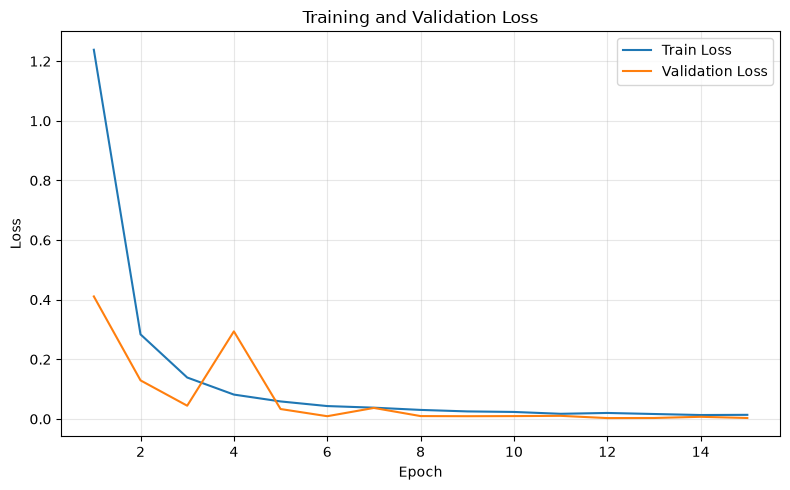

In [17]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_loss"], label="Train Loss")
plt.plot(epochs_range, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Cell 18. Vẽ biểu đồ Accuracy

Accuracy cho biết tỷ lệ dự đoán đúng trên tổng số ảnh.

So sánh train accuracy và validation accuracy để xem model có tổng quát hóa tốt hay chỉ ghi nhớ dữ liệu train.


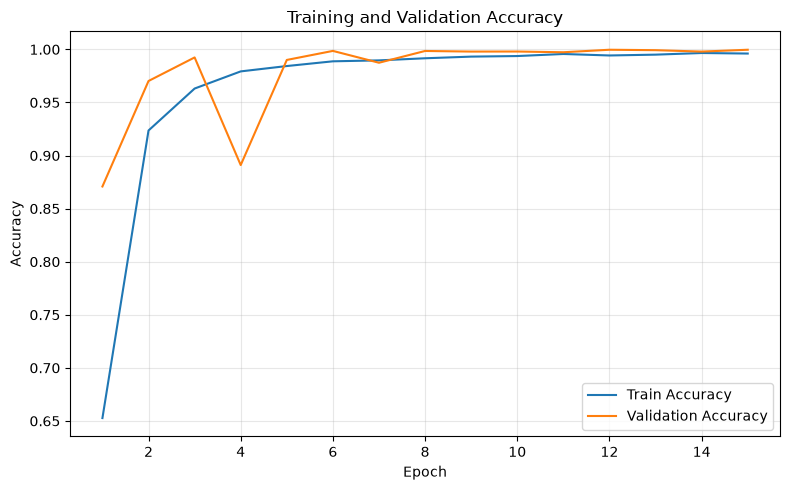

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_accuracy"], label="Train Accuracy")
plt.plot(epochs_range, history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Cell 19. Nạp checkpoint tốt nhất

Không mặc định dùng trọng số ở epoch cuối. Nạp lại checkpoint có validation loss thấp nhất để đánh giá.

`weights_only=True` được dùng khi phiên bản PyTorch hỗ trợ.


In [19]:
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError("Chưa có checkpoint. Hãy chạy Cell 15 trước.")

try:
    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint.")
print("Best validation loss:", checkpoint["best_val_loss"])


Loaded best checkpoint.
Best validation loss: 0.002939639318581863


## Cell 20. Đánh giá chi tiết trên Validation

Thu thập nhãn thật và nhãn dự đoán của toàn bộ validation set.

Báo cáo gồm:
- Precision: trong các dự đoán thuộc một lớp, tỷ lệ dự đoán đúng.
- Recall: trong các ảnh thật thuộc một lớp, tỷ lệ được nhận diện đúng.
- F1-score: trung bình điều hòa giữa precision và recall.
- Support: số ảnh thật của lớp đó.

Đây vẫn là kết quả validation, chưa phải kết quả trên một test set độc lập.


In [20]:
all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for batch_images, batch_labels in val_loader:
        batch_images = batch_images.to(DEVICE)
        logits = model(batch_images)
        predictions = logits.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions.tolist())
        all_labels.extend(batch_labels.numpy().tolist())

val_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Validation Accuracy: {val_accuracy:.4%}")
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))


Validation Accuracy: 99.9655%

Classification Report:
              precision    recall  f1-score   support

           A       1.00      1.00      1.00       600
           B       1.00      1.00      1.00       600
           C       1.00      1.00      1.00       600
           D       1.00      1.00      1.00       600
           E       1.00      1.00      1.00       600
           F       1.00      1.00      1.00       600
           G       1.00      1.00      1.00       600
           H       1.00      1.00      1.00       600
           I       1.00      1.00      1.00       600
           J       1.00      1.00      1.00       600
           K       1.00      1.00      1.00       600
           L       1.00      1.00      1.00       600
           M       1.00      1.00      1.00       600
           N       1.00      1.00      1.00       600
           O       1.00      1.00      1.00       600
           P       1.00      1.00      1.00       600
           Q       1.00    

## Cell 21. Confusion Matrix

Confusion Matrix cho biết model thường nhầm class nào thành class nào.

- Trục dọc: nhãn thật.
- Trục ngang: nhãn dự đoán.
- Các giá trị trên đường chéo: dự đoán đúng.

Nếu hai class thường nhầm lẫn, hãy kiểm tra ảnh mẫu của hai class đó và cân nhắc bổ sung dữ liệu hoặc điều chỉnh mô hình.


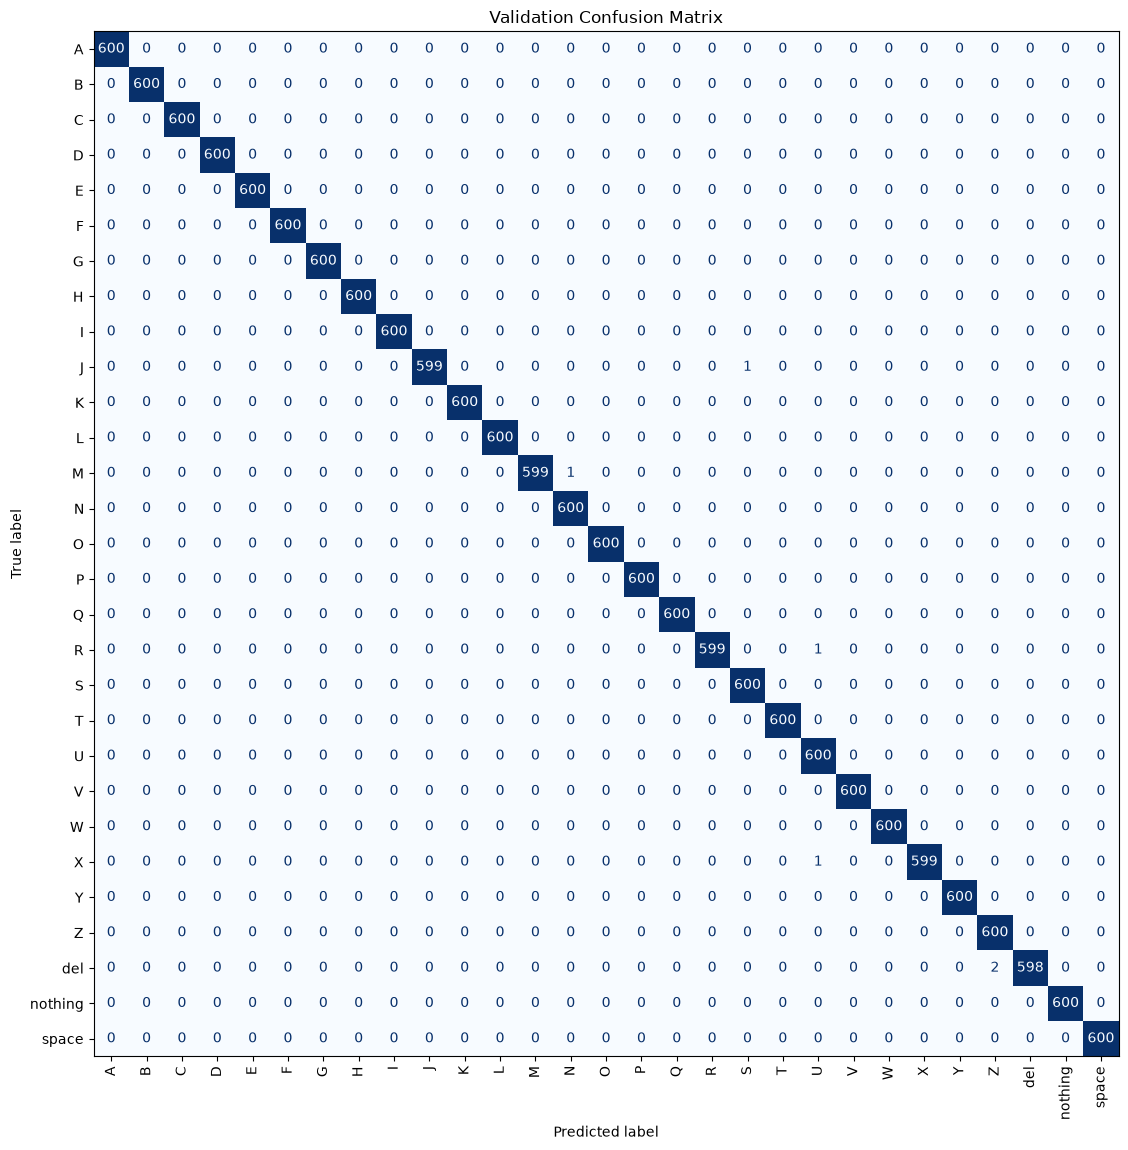

In [21]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(max(10, NUM_CLASSES * 0.45), max(8, NUM_CLASSES * 0.4)))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


## Cell 22. Thử dự đoán một ảnh validation

Chọn một ảnh từ validation set, đưa qua đúng transform validation, rồi hiển thị:
- Ảnh đầu vào.
- Nhãn thật.
- Nhãn dự đoán.
- Confidence ước tính từ Softmax.

Confidence không đồng nghĩa với xác suất model chắc chắn đúng, đặc biệt khi dữ liệu webcam khác dữ liệu train.


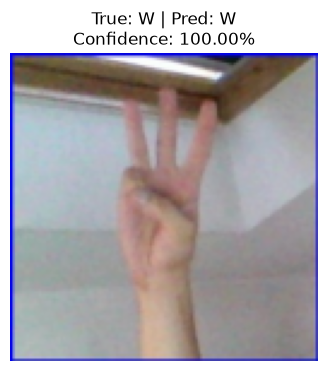

In [22]:
sample_index = random.randrange(len(val_dataset))
sample_image, sample_label = val_dataset[sample_index]

model.eval()
with torch.no_grad():
    logits = model(sample_image.unsqueeze(0).to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)[0]
    predicted_idx = int(probabilities.argmax().item())
    confidence = float(probabilities[predicted_idx].item())

# Khôi phục ảnh gần đúng để hiển thị sau Normalize
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
display_image = (sample_image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

plt.figure(figsize=(4, 4))
plt.imshow(display_image)
plt.axis("off")
plt.title(
    f"True: {class_names[sample_label]} | "
    f"Pred: {class_names[predicted_idx]}\n"
    f"Confidence: {confidence:.2%}"
)
plt.show()


## Cell 23. Kiểm tra các file đầu ra

Sau khi huấn luyện, thư mục `models/` dự kiến có:

```text
models/
├── best_model.pth
├── class_names.json
└── training_history.csv
```

Ý nghĩa:
- `best_model.pth`: trọng số tốt nhất và metadata cần thiết để nạp model.
- `class_names.json`: thứ tự nhãn để giải mã dự đoán.
- `training_history.csv`: lịch sử train/validation.

Đây là các file được tạo ra bởi notebook, không phải file dataset.


In [23]:
for path in [BEST_MODEL_PATH, CLASS_NAMES_PATH, HISTORY_PATH]:
    if path.exists():
        print(f"[OK] {path.name} - {path.stat().st_size / 1024:.1f} KB")
    else:
        print(f"[MISSING] {path.name}")


[OK] best_model.pth - 1564.4 KB
[OK] class_names.json - 0.2 KB
[OK] training_history.csv - 1.2 KB


## Kết luận và bước tiếp theo

Sau notebook này, bạn đã có:
1. Một CNN baseline được huấn luyện bằng PyTorch.
2. Checkpoint có validation loss tốt nhất.
3. Class mapping để giải mã kết quả dự đoán.
4. Biểu đồ loss/accuracy và báo cáo phân loại.
5. Confusion Matrix để phân tích các class dễ nhầm.

### Trước khi chuyển sang webcam

- Kiểm tra validation accuracy và các class có recall thấp.
- Xem confusion matrix để tìm các cặp class dễ nhầm.
- Thử ảnh mới không nằm trong tập train/validation.
- Không coi validation accuracy là kết quả test cuối cùng.

**Notebook tiếp theo:** `03_model_evaluation.ipynb` hoặc phần triển khai webcam, tùy cấu trúc dự án.

Khi triển khai webcam, cần dùng đúng kiến trúc CNN, `IMAGE_SIZE`, normalization và `class_names` đã lưu ở đây. Webcam có thể cần thêm bước phát hiện/crop vùng bàn tay nếu ảnh đầu vào khác đáng kể so với dataset.
